In [1]:
!pip -q install earthengine-api geemap rasterio numpy matplotlib \
    scikit-learn segmentation-models-pytorch folium scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 77.2 MB/s eta 0:00:00


In [2]:
import torch
import rasterio
import numpy as np
import segmentation_models_pytorch as smp

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("All required libraries imported successfully!")

PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4
All required libraries imported successfully!


In [3]:
import ee

ee.Authenticate()

In [4]:
import ee

PROJECT_ID = "deforestation-detection-511216"

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

print("Earth Engine connected successfully!")

Earth Engine connected successfully!


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [5]:
collection = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterDate("2024-01-01", "2024-02-01")
    .filterBounds(ee.Geometry.Point([78.5, 15.8]))
)

print("Available Sentinel-2 scenes:", collection.size().getInfo())

Available Sentinel-2 scenes: 12


In [6]:
import ee

# Small study area near Novo Progresso, Brazilian Amazon
AOI = ee.Geometry.Rectangle([
    -55.43, -7.18,
    -55.38, -7.13
])

# Compare the same season in two years
DATE_1_START = "2023-07-01"
DATE_1_END   = "2023-08-01"

DATE_2_START = "2024-07-01"
DATE_2_END   = "2024-08-01"

def get_sentinel_collection(start_date, end_date):
    return (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(AOI)
        .filterDate(start_date, end_date)
        .filter(
            ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40)
        )
    )

collection_t1 = get_sentinel_collection(
    DATE_1_START, DATE_1_END
)

collection_t2 = get_sentinel_collection(
    DATE_2_START, DATE_2_END
)

print("2023 candidate scenes:", collection_t1.size().getInfo())
print("2024 candidate scenes:", collection_t2.size().getInfo())

2023 candidate scenes: 5
2024 candidate scenes: 6


In [7]:
import ee

# Six Sentinel-2 bands for the U-Net model
BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]

def prepare_composite(start_date, end_date):
    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(AOI)
        .filterDate(start_date, end_date)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(lambda image: image.updateMask(
            image.select("SCL").neq(3)    # Cloud shadow
            .And(image.select("SCL").neq(8))  # Medium cloud
            .And(image.select("SCL").neq(9))  # High cloud
            .And(image.select("SCL").neq(10)) # Cirrus
            .And(image.select("SCL").neq(11)) # Snow/ice
        ))
    )

    return (
        collection.select(BANDS)
        .median()
        .clip(AOI)
        .divide(10000)
        .toFloat()
    )

image_t1 = prepare_composite(DATE_1_START, DATE_1_END)
image_t2 = prepare_composite(DATE_2_START, DATE_2_END)

print("2023 composite bands:", image_t1.bandNames().getInfo())
print("2024 composite bands:", image_t2.bandNames().getInfo())

2023 composite bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
2024 composite bands: ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']


In [8]:
def prepare_forest_labels(start_date, end_date):
    dw = (
        ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
        .filterBounds(AOI)
        .filterDate(start_date, end_date)
        .select(["label", "trees"])
    )

    # Median tree probability over the selected period
    tree_probability = dw.select("trees").median()

    # Use the most common predicted land-cover class
    land_cover = dw.select("label").mode()

    # Forest candidate: trees is the dominant class
    forest_mask = land_cover.eq(1)

    return forest_mask.rename("forest").toByte()

forest_t1 = prepare_forest_labels(DATE_1_START, DATE_1_END)
forest_t2 = prepare_forest_labels(DATE_2_START, DATE_2_END)

print("2023 label bands:", forest_t1.bandNames().getInfo())
print("2024 label bands:", forest_t2.bandNames().getInfo())

2023 label bands: ['forest']
2024 label bands: ['forest']


In [9]:
import geemap

Map = geemap.Map()

# Center the map on the study area
Map.centerObject(AOI, 12)

# Natural-color satellite image: B4 (red), B3 (green), B2 (blue)
rgb_vis = {
    "bands": ["B4", "B3", "B2"],
    "min": 0.0,
    "max": 0.3
}

# Forest labels: white = predicted forest
forest_vis = {
    "min": 0,
    "max": 1,
    "palette": ["000000", "00FF00"]
}

Map.addLayer(image_t1, rgb_vis, "Satellite - July 2023")
Map.addLayer(image_t2, rgb_vis, "Satellite - July 2024")
Map.addLayer(forest_t1, forest_vis, "Forest labels - 2023")
Map.addLayer(forest_t2, forest_vis, "Forest labels - 2024")

Map.addLayer(AOI, {}, "Study area")
Map

Map(center=[-7.15500021760178, -55.40499999999843], controls=(WidgetControl(options=['position', 'transparent_…

In [10]:
import numpy as np
import geemap

# Export the 2023 and 2024 images as NumPy arrays
arr_t1 = geemap.ee_to_numpy(
    image_t1,
    region=AOI,
    scale=10
)

arr_t2 = geemap.ee_to_numpy(
    image_t2,
    region=AOI,
    scale=10
)

labels_t1 = geemap.ee_to_numpy(
    forest_t1,
    region=AOI,
    scale=10
)

labels_t2 = geemap.ee_to_numpy(
    forest_t2,
    region=AOI,
    scale=10
)

print("2023 image shape:", arr_t1.shape)
print("2024 image shape:", arr_t2.shape)
print("2023 labels shape:", labels_t1.shape)
print("2024 labels shape:", labels_t2.shape)

2023 image shape: (558, 557, 6)
2024 image shape: (558, 557, 6)
2023 labels shape: (558, 557, 1)
2024 labels shape: (558, 557, 1)


In [11]:
import numpy as np

def inspect_data(name, image, labels=None):
    image = np.asarray(image)
    print(f"\n--- {name} ---")
    print("Image shape:", image.shape)
    print("Missing or invalid values:", np.size(image) - np.isfinite(image).sum())
    print("Minimum:", np.nanmin(image))
    print("Maximum:", np.nanmax(image))

    if labels is not None:
        labels = np.asarray(labels).squeeze()
        valid = np.isfinite(labels)
        values, counts = np.unique(labels[valid], return_counts=True)

        print("Label values:", values)
        print("Label counts:", counts)
        print("Valid label pixels:", valid.sum())

inspect_data("2023", arr_t1, labels_t1)
inspect_data("2024", arr_t2, labels_t2)


--- 2023 ---
Image shape: (558, 557, 6)
Missing or invalid values: 0
Minimum: 0.0025
Maximum: 0.617
Label values: [0 1]
Label counts: [ 90038 220768]
Valid label pixels: 310806

--- 2024 ---
Image shape: (558, 557, 6)
Missing or invalid values: 0
Minimum: 0.0038
Maximum: 0.65155
Label values: [0 1]
Label counts: [ 89905 220901]
Valid label pixels: 310806


In [12]:
import numpy as np

TILE_SIZE = 256

# Remove the final singleton dimension from forest labels
mask_t1 = labels_t1.squeeze().astype(np.uint8)

# Check that the satellite data and labels align
assert arr_t1.shape[:2] == mask_t1.shape
assert arr_t1.shape[2] == 6

image_tiles = []
mask_tiles = []

height, width, _ = arr_t1.shape

for row in range(0, height - TILE_SIZE + 1, TILE_SIZE):
    for col in range(0, width - TILE_SIZE + 1, TILE_SIZE):

        image_tile = arr_t1[
            row:row + TILE_SIZE,
            col:col + TILE_SIZE,
            :
        ]

        mask_tile = mask_t1[
            row:row + TILE_SIZE,
            col:col + TILE_SIZE
        ]

        # Skip tiles with invalid satellite values
        if not np.isfinite(image_tile).all():
            continue

        image_tiles.append(image_tile)
        mask_tiles.append(mask_tile)

X_tiles = np.array(image_tiles, dtype=np.float32)
y_tiles = np.array(mask_tiles, dtype=np.uint8)

print("Image tiles:", X_tiles.shape)
print("Mask tiles:", y_tiles.shape)

Image tiles: (4, 256, 256, 6)
Mask tiles: (4, 256, 256)


In [13]:
print("Number of image tiles:", len(X_tiles))
print("Number of mask tiles:", len(y_tiles))

if len(y_tiles) > 0:
    for i in range(len(y_tiles)):
        values, counts = np.unique(y_tiles[i], return_counts=True)
        print(f"\nTile {i + 1}:")
        print("Label values:", values)
        print("Pixel counts:", counts)
        print("Forest percentage:",
              round(100 * np.mean(y_tiles[i] == 1), 2), "%")

Number of image tiles: 4
Number of mask tiles: 4

Tile 1:
Label values: [0 1]
Pixel counts: [ 5496 60040]
Forest percentage: 91.61 %

Tile 2:
Label values: [0 1]
Pixel counts: [45598 19938]
Forest percentage: 30.42 %

Tile 3:
Label values: [0 1]
Pixel counts: [ 3848 61688]
Forest percentage: 94.13 %

Tile 4:
Label values: [0 1]
Pixel counts: [10281 55255]
Forest percentage: 84.31 %


In [14]:
# Expand the study area around our original location
AOI = ee.Geometry.Rectangle([
    -55.48, -7.23,
    -55.33, -7.08
])

print("Expanded study area set successfully!")

print(
    "2023 candidate scenes:",
    get_sentinel_collection(
        DATE_1_START, DATE_1_END
    ).size().getInfo()
)

print(
    "2024 candidate scenes:",
    get_sentinel_collection(
        DATE_2_START, DATE_2_END
    ).size().getInfo()
)

Expanded study area set successfully!
2023 candidate scenes: 5
2024 candidate scenes: 6


In [16]:
import numpy as np
import geemap

# Download each image in smaller geographic sections
# so each Earth Engine response stays below the size limit.

def download_in_parts(image, region, scale=10, parts=2):
    bounds = region.bounds()
    coords = bounds.coordinates().getInfo()[0]

    xmin = min(p[0] for p in coords)
    xmax = max(p[0] for p in coords)
    ymin = min(p[1] for p in coords)
    ymax = max(p[1] for p in coords)

    chunks = []

    for i in range(parts):
        for j in range(parts):
            x0 = xmin + (xmax - xmin) * i / parts
            x1 = xmin + (xmax - xmin) * (i + 1) / parts
            y0 = ymin + (ymax - ymin) * j / parts
            y1 = ymin + (ymax - ymin) * (j + 1) / parts

            chunk_region = ee.Geometry.Rectangle(
                [x0, y0, x1, y1], proj="EPSG:4326",
                geodesic=False
            )

            arr = geemap.ee_to_numpy(
                image, region=chunk_region, scale=scale
            )
            chunks.append((i, j, arr))

    return chunks

image_parts_t1 = download_in_parts(image_t1, AOI, parts=2)
image_parts_t2 = download_in_parts(image_t2, AOI, parts=2)
label_parts_t1 = download_in_parts(forest_t1, AOI, parts=2)
label_parts_t2 = download_in_parts(forest_t2, AOI, parts=2)

print("Downloaded image sections for both dates.")
print("2023 sections:", len(image_parts_t1))
print("2024 sections:", len(image_parts_t2))

Downloaded image sections for both dates.
2023 sections: 4
2024 sections: 4


In [17]:
print("2023 image sections:", len(image_parts_t1))
print("2024 image sections:", len(image_parts_t2))
print("2023 label sections:", len(label_parts_t1))
print("2024 label sections:", len(label_parts_t2))

print("\nSection shapes:")
for i, (row, col, arr) in enumerate(image_parts_t1):
    print(f"2023 image section {i+1}: {arr.shape}")

for i, (row, col, arr) in enumerate(label_parts_t1):
    print(f"2023 label section {i+1}: {arr.shape}")

2023 image sections: 4
2024 image sections: 4
2023 label sections: 4
2024 label sections: 4

Section shapes:
2023 image section 1: (836, 836, 6)
2023 image section 2: (836, 836, 6)
2023 image section 3: (836, 836, 6)
2023 image section 4: (836, 836, 6)
2023 label section 1: (836, 836, 1)
2023 label section 2: (836, 836, 1)
2023 label section 3: (836, 836, 1)
2023 label section 4: (836, 836, 1)


In [18]:
# Check each downloaded section for matching dimensions

for k in range(len(image_parts_t1)):
    img = image_parts_t1[k][2]
    lbl = label_parts_t1[k][2]

    print(f"\nSection {k + 1}")
    print("Image shape:", img.shape)
    print("Label shape:", lbl.shape)
    print("Image finite:", np.isfinite(img).all())
    print("Label values:", np.unique(lbl))


Section 1
Image shape: (836, 836, 6)
Label shape: (836, 836, 1)
Image finite: False
Label values: [0 1]

Section 2
Image shape: (836, 836, 6)
Label shape: (836, 836, 1)
Image finite: True
Label values: [0 1]

Section 3
Image shape: (836, 836, 6)
Label shape: (836, 836, 1)
Image finite: False
Label values: [0 1]

Section 4
Image shape: (836, 836, 6)
Label shape: (836, 836, 1)
Image finite: True
Label values: [0 1]


In [19]:
TILE_SIZE = 256

X_tiles = []
y_tiles = []
tile_locations = []

for section_idx, (row, col, img) in enumerate(image_parts_t1):
    lbl = label_parts_t1[section_idx][2]

    # Remove the single label-band dimension
    lbl = lbl.squeeze(axis=-1)

    assert img.shape[:2] == lbl.shape

    height, width, _ = img.shape

    for r in range(0, height - TILE_SIZE + 1, TILE_SIZE):
        for c in range(0, width - TILE_SIZE + 1, TILE_SIZE):

            image_tile = img[r:r+TILE_SIZE, c:c+TILE_SIZE, :]
            label_tile = lbl[r:r+TILE_SIZE, c:c+TILE_SIZE]

            # Skip tiles with missing or infinite imagery
            if not np.isfinite(image_tile).all():
                continue

            X_tiles.append(image_tile.astype(np.float32))
            y_tiles.append(label_tile.astype(np.uint8))
            tile_locations.append((section_idx, r, c))

X_tiles = np.asarray(X_tiles, dtype=np.float32)
y_tiles = np.asarray(y_tiles, dtype=np.uint8)

print("Valid image tiles:", X_tiles.shape)
print("Valid label tiles:", y_tiles.shape)
print("Total valid tiles:", len(X_tiles))

Valid image tiles: (36, 256, 256, 6)
Valid label tiles: (36, 256, 256)
Total valid tiles: 36


In [20]:
print("Total valid tiles:", len(X_tiles))
print("Image dataset shape:", X_tiles.shape)
print("Label dataset shape:", y_tiles.shape)

for i in range(len(y_tiles)):
    forest_percentage = 100 * np.mean(y_tiles[i] == 1)
    print(
        f"Tile {i + 1}: "
        f"Forest = {forest_percentage:.2f}%"
    )

Total valid tiles: 36
Image dataset shape: (36, 256, 256, 6)
Label dataset shape: (36, 256, 256)
Tile 1: Forest = 77.99%
Tile 2: Forest = 55.10%
Tile 3: Forest = 93.19%
Tile 4: Forest = 58.73%
Tile 5: Forest = 84.90%
Tile 6: Forest = 82.57%
Tile 7: Forest = 78.56%
Tile 8: Forest = 93.87%
Tile 9: Forest = 98.60%
Tile 10: Forest = 32.12%
Tile 11: Forest = 81.05%
Tile 12: Forest = 55.77%
Tile 13: Forest = 69.82%
Tile 14: Forest = 79.44%
Tile 15: Forest = 71.44%
Tile 16: Forest = 66.25%
Tile 17: Forest = 60.26%
Tile 18: Forest = 93.96%
Tile 19: Forest = 75.90%
Tile 20: Forest = 40.22%
Tile 21: Forest = 42.49%
Tile 22: Forest = 73.18%
Tile 23: Forest = 32.91%
Tile 24: Forest = 52.74%
Tile 25: Forest = 79.75%
Tile 26: Forest = 34.84%
Tile 27: Forest = 14.10%
Tile 28: Forest = 38.32%
Tile 29: Forest = 76.86%
Tile 30: Forest = 99.88%
Tile 31: Forest = 33.86%
Tile 32: Forest = 36.22%
Tile 33: Forest = 75.71%
Tile 34: Forest = 19.04%
Tile 35: Forest = 46.59%
Tile 36: Forest = 70.11%


In [21]:
from collections import Counter

# Count how many valid tiles came from each section
section_counts = Counter(
    location[0] for location in tile_locations
)

print("Valid tiles by geographic section:")
for section, count in sorted(section_counts.items()):
    print(f"Section {section + 1}: {count} tiles")

print("\nTotal tiles:", len(X_tiles))
print("All image values finite:", np.isfinite(X_tiles).all())
print("Label classes:", np.unique(y_tiles))

Valid tiles by geographic section:
Section 1: 9 tiles
Section 2: 9 tiles
Section 3: 9 tiles
Section 4: 9 tiles

Total tiles: 36
All image values finite: True
Label classes: [0 1]


In [22]:
import numpy as np

# Use sections 1 and 3 for training,
# and sections 2 and 4 for geographic testing.
train_sections = {0, 2}
test_sections = {1, 3}

train_idx = [
    i for i, loc in enumerate(tile_locations)
    if loc[0] in train_sections
]

test_idx = [
    i for i, loc in enumerate(tile_locations)
    if loc[0] in test_sections
]

X_train = X_tiles[train_idx]
y_train = y_tiles[train_idx]

X_test = X_tiles[test_idx]
y_test = y_tiles[test_idx]

print("Training tiles:", len(X_train))
print("Testing tiles:", len(X_test))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training tiles: 18
Testing tiles: 18
Training shape: (18, 256, 256, 6)
Testing shape: (18, 256, 256, 6)


In [23]:
# Calculate per-band statistics using training pixels only
band_mean = X_train.reshape(-1, 6).mean(axis=0)
band_std = X_train.reshape(-1, 6).std(axis=0)

# Avoid division by zero
band_std[band_std == 0] = 1.0

X_train_norm = (X_train - band_mean) / band_std
X_test_norm = (X_test - band_mean) / band_std

print("Training data finite:", np.isfinite(X_train_norm).all())
print("Testing data finite:", np.isfinite(X_test_norm).all())
print("Band means:", band_mean)
print("Band standard deviations:", band_std)

Training data finite: True
Testing data finite: True
Band means: [0.035793   0.05808847 0.05661597 0.28662243 0.23075138 0.12582715]
Band standard deviations: [0.02481999 0.03167205 0.05593644 0.05801072 0.11047962 0.08717797]


**U-Net model using PyTorch**

In [24]:
!pip -q install segmentation-models-pytorch

In [25]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import numpy as np

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Check that the geographic split worked
print("Training tiles:", len(X_train))
print("Testing tiles:", len(X_test))

assert len(X_train) > 0, "Training set is empty"
assert len(X_test) > 0, "Testing set is empty"

# U-Net with a pretrained ResNet-34 encoder
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=6,
    classes=1,
    activation=None
).to(device)

print("U-Net model created successfully.")

Device: cuda
Training tiles: 18
Testing tiles: 18


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

U-Net model created successfully.


In [26]:
class ForestDataset(Dataset):
    def __init__(self, images, masks):
        # Convert images from (N, H, W, C) to (N, C, H, W)
        self.images = torch.from_numpy(
            images.transpose(0, 3, 1, 2).astype(np.float32)
        )

        # Convert masks to (N, 1, H, W)
        self.masks = torch.from_numpy(
            masks[:, None, :, :].astype(np.float32)
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.images[index], self.masks[index]


# Create training and testing datasets
train_dataset = ForestDataset(X_train_norm, y_train)
test_dataset = ForestDataset(X_test_norm, y_test)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Dataset preparation completed.")

Training samples: 18
Testing samples: 18
Dataset preparation completed.


In [27]:
# Binary Cross-Entropy loss
bce_loss = nn.BCEWithLogitsLoss()

# Dice loss for segmentation
dice_loss = smp.losses.DiceLoss(
    mode="binary",
    from_logits=True
)

# Combine both losses
def combined_loss(predictions, targets):
    return (
        bce_loss(predictions, targets)
        + dice_loss(predictions, targets)
    )

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss function and optimizer are ready.")

Loss function and optimizer are ready.


In [28]:
EPOCHS = 10

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = combined_loss(predictions, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"- Training Loss: {average_loss:.4f}"
    )

print("Training completed.")

Epoch [1/10] - Training Loss: 1.0006
Epoch [2/10] - Training Loss: 0.8704
Epoch [3/10] - Training Loss: 0.7650
Epoch [4/10] - Training Loss: 0.6947
Epoch [5/10] - Training Loss: 0.6301
Epoch [6/10] - Training Loss: 0.5434
Epoch [7/10] - Training Loss: 0.5007
Epoch [8/10] - Training Loss: 0.5226
Epoch [9/10] - Training Loss: 0.4226
Epoch [10/10] - Training Loss: 0.3917
Training completed.


In [29]:
from sklearn.metrics import f1_score, jaccard_score
import numpy as np
import torch

model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)

        logits = model(images)
        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).cpu().numpy()
        targets = masks.numpy()

        all_predictions.append(predictions.reshape(-1))
        all_targets.append(targets.reshape(-1))

y_pred = np.concatenate(all_predictions).astype(np.uint8)
y_true = np.concatenate(all_targets).astype(np.uint8)

iou = jaccard_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print(f"Forest IoU: {iou:.4f}")
print(f"Forest F1-score: {f1:.4f}")

Forest IoU: 0.8830
Forest F1-score: 0.9379


In [30]:
from sklearn.metrics import f1_score, jaccard_score
import numpy as np

# Use the original, unnormalized satellite images
# B4 = index 2, B8 = index 3
red = X_test[..., 2]
nir = X_test[..., 3]

denominator = nir + red

ndvi = np.divide(
    nir - red,
    denominator,
    out=np.zeros_like(nir, dtype=np.float32),
    where=np.abs(denominator) > 1e-8
)

# Simple forest baseline: NDVI > 0.6
ndvi_pred = (ndvi > 0.6).astype(np.uint8)

# Evaluate against the same reference masks
y_true_ndvi = y_test.reshape(-1).astype(np.uint8)
y_pred_ndvi = ndvi_pred.reshape(-1)

ndvi_iou = jaccard_score(
    y_true_ndvi, y_pred_ndvi, zero_division=0
)
ndvi_f1 = f1_score(
    y_true_ndvi, y_pred_ndvi, zero_division=0
)

print(f"NDVI Baseline IoU: {ndvi_iou:.4f}")
print(f"NDVI Baseline F1-score: {ndvi_f1:.4f}")

NDVI Baseline IoU: 0.9048
NDVI Baseline F1-score: 0.9500


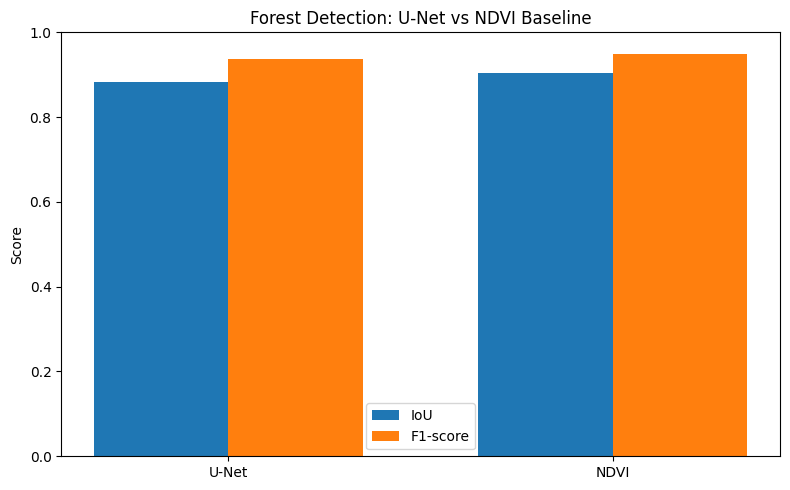

In [31]:
import matplotlib.pyplot as plt
import numpy as np

models = ["U-Net", "NDVI"]
iou_scores = [0.8830, 0.9048]
f1_scores = [0.9379, 0.9500]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, iou_scores, width, label="IoU")
plt.bar(x + width/2, f1_scores, width, label="F1-score")

plt.xticks(x, models)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Forest Detection: U-Net vs NDVI Baseline")
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
TILE_SIZE = 256

X_2023 = []
X_2024 = []
Y_2023 = []
Y_2024 = []
change_tile_locations = []

for section_idx in range(len(image_parts_t1)):
    img1 = image_parts_t1[section_idx][2]
    img2 = image_parts_t2[section_idx][2]

    lbl1 = label_parts_t1[section_idx][2].squeeze(axis=-1)
    lbl2 = label_parts_t2[section_idx][2].squeeze(axis=-1)

    # Confirm that dates and labels are spatially aligned
    if not (
        img1.shape == img2.shape
        and img1.shape[:2] == lbl1.shape
        and img1.shape[:2] == lbl2.shape
    ):
        raise ValueError(
            f"Shape mismatch in geographic section {section_idx}"
        )

    height, width = img1.shape[:2]

    for r in range(0, height - TILE_SIZE + 1, TILE_SIZE):
        for c in range(0, width - TILE_SIZE + 1, TILE_SIZE):

            a = img1[r:r+TILE_SIZE, c:c+TILE_SIZE, :]
            b = img2[r:r+TILE_SIZE, c:c+TILE_SIZE, :]

            ya = lbl1[r:r+TILE_SIZE, c:c+TILE_SIZE]
            yb = lbl2[r:r+TILE_SIZE, c:c+TILE_SIZE]

            # Keep only tiles with valid observations on both dates
            if not (
                np.isfinite(a).all()
                and np.isfinite(b).all()
            ):
                continue

            X_2023.append(a.astype(np.float32))
            X_2024.append(b.astype(np.float32))
            Y_2023.append(ya.astype(np.uint8))
            Y_2024.append(yb.astype(np.uint8))

            change_tile_locations.append(
                (section_idx, r, c)
            )

X_2023 = np.asarray(X_2023, dtype=np.float32)
X_2024 = np.asarray(X_2024, dtype=np.float32)
Y_2023 = np.asarray(Y_2023, dtype=np.uint8)
Y_2024 = np.asarray(Y_2024, dtype=np.uint8)

print("Aligned tiles:", len(X_2023))
print("2023 images:", X_2023.shape)
print("2024 images:", X_2024.shape)
print("2023 labels:", Y_2023.shape)
print("2024 labels:", Y_2024.shape)

Aligned tiles: 36
2023 images: (36, 256, 256, 6)
2024 images: (36, 256, 256, 6)
2023 labels: (36, 256, 256)
2024 labels: (36, 256, 256)


In [33]:
def predict_forest_masks(images, batch_size=4):
    model.eval()
    predictions = []

    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            batch = images[start:start + batch_size]

            # Use training-set statistics only
            batch = (batch - band_mean) / band_std

            batch_tensor = torch.from_numpy(
                batch.transpose(0, 3, 1, 2).astype(np.float32)
            ).to(device)

            logits = model(batch_tensor)
            probs = torch.sigmoid(logits)

            predictions.append(
                (probs >= 0.5).cpu().numpy()[:, 0]
            )

    if not predictions:
        raise ValueError("No aligned tiles available for prediction.")

    return np.concatenate(predictions).astype(np.uint8)


pred_2023 = predict_forest_masks(X_2023)
pred_2024 = predict_forest_masks(X_2024)

print("2023 predictions:", pred_2023.shape)
print("2024 predictions:", pred_2024.shape)
print("Prediction classes, 2023:", np.unique(pred_2023))
print("Prediction classes, 2024:", np.unique(pred_2024))

2023 predictions: (36, 256, 256)
2024 predictions: (36, 256, 256)
Prediction classes, 2023: [0 1]
Prediction classes, 2024: [0 1]


**Forest Loss**

In [34]:
from scipy import ndimage
import numpy as np

# 1 = forest, 0 = non-forest
potential_loss = (
    (pred_2023 == 1) &
    (pred_2024 == 0)
)

# Remove connected components smaller than 50 pixels
clean_loss = np.zeros_like(potential_loss, dtype=bool)

structure = np.ones((3, 3), dtype=np.uint8)

for i in range(len(potential_loss)):
    labeled, number = ndimage.label(
        potential_loss[i],
        structure=structure
    )

    if number == 0:
        continue

    component_sizes = np.bincount(labeled.ravel())

    keep = component_sizes >= 50
    keep[0] = False  # Background is never a clearing region

    clean_loss[i] = keep[labeled]

print("Potential clearing pixels before filtering:",
      int(potential_loss.sum()))

print("Potential clearing pixels after filtering:",
      int(clean_loss.sum()))

print("Tiles with potential clearing:",
      int(clean_loss.reshape(len(clean_loss), -1).any(axis=1).sum()))

Potential clearing pixels before filtering: 63099
Potential clearing pixels after filtering: 39665
Tiles with potential clearing: 30


In [35]:
# Each 10 m pixel represents approximately 0.01 hectares
PIXEL_AREA_HECTARES = 0.01

total_loss_pixels = int(clean_loss.sum())
estimated_loss_hectares = (
    total_loss_pixels * PIXEL_AREA_HECTARES
)

print("Potential clearing pixels:", total_loss_pixels)
print(f"Estimated potential clearing: {estimated_loss_hectares:.2f} hectares")
print(f"Estimated potential clearing: {estimated_loss_hectares:.4f} km²")

Potential clearing pixels: 39665
Estimated potential clearing: 396.65 hectares
Estimated potential clearing: 396.6500 km²


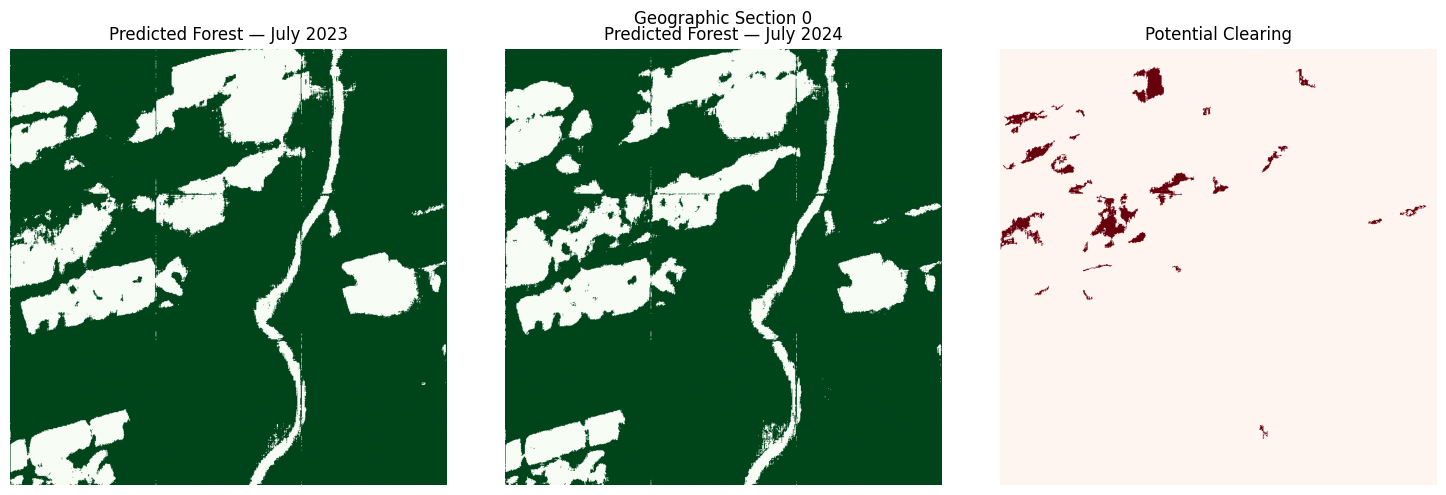

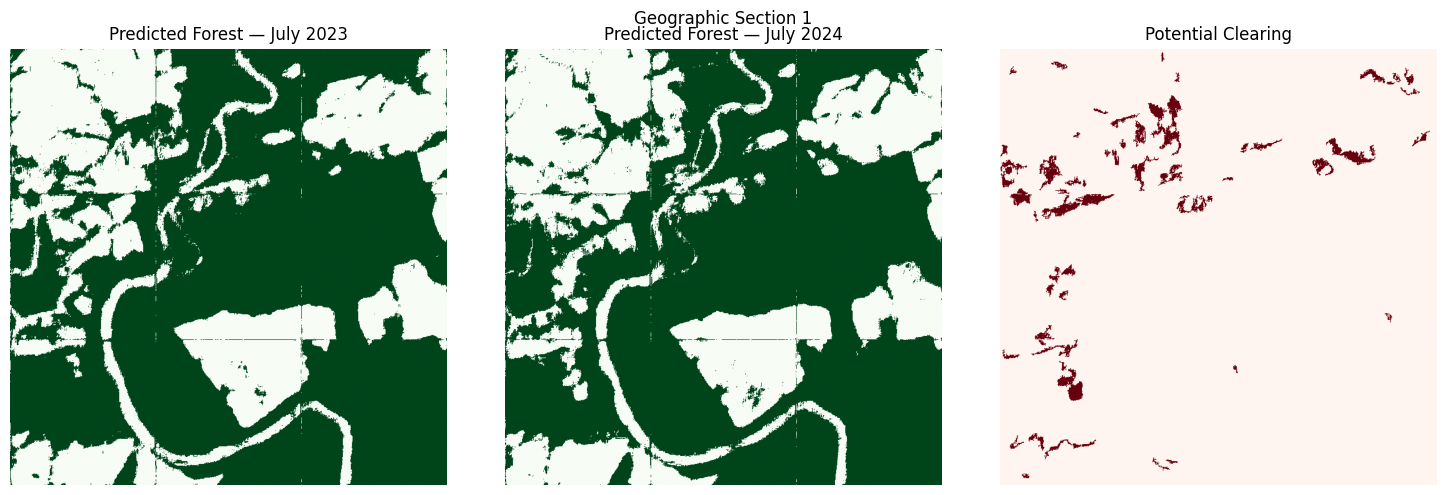

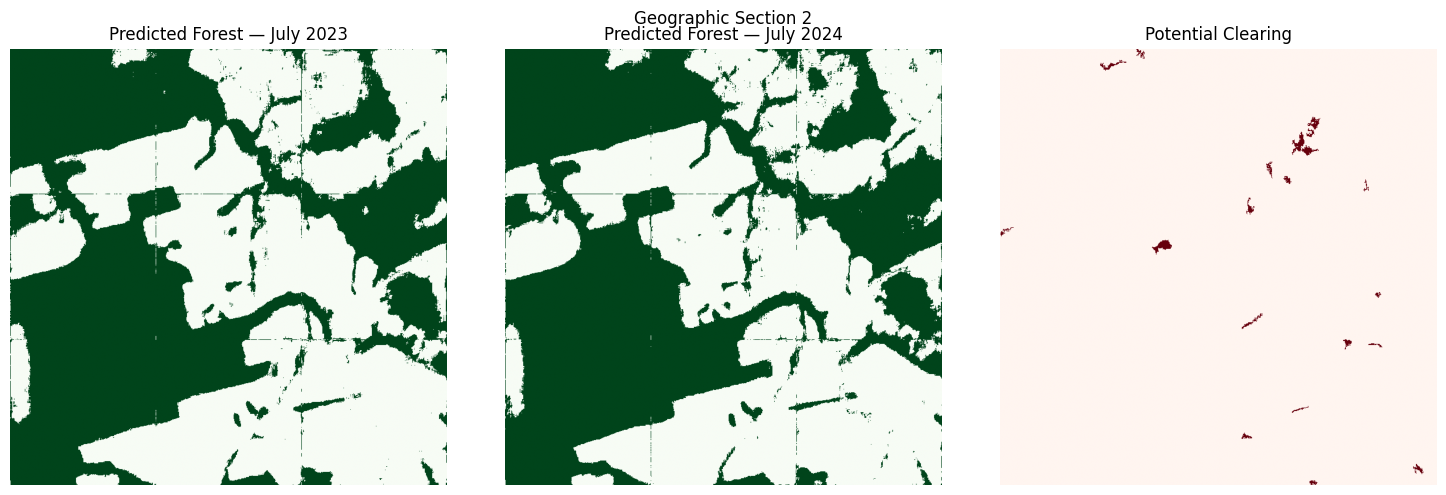

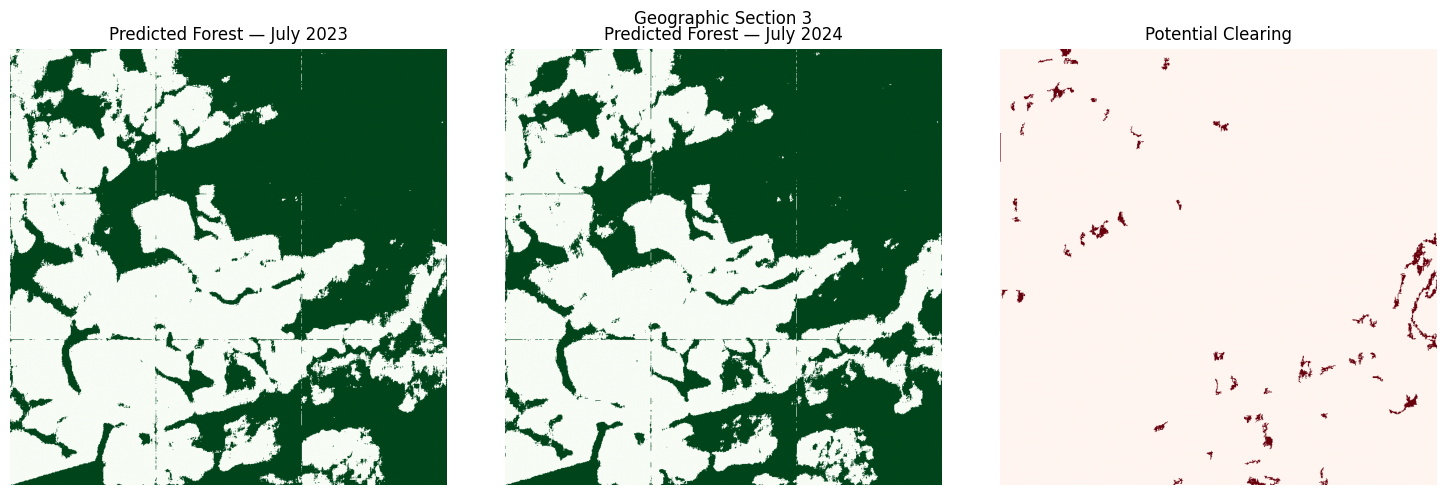

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Combine aligned tiles into a display grid for each date
def make_mosaic(tiles, locations):
    sections = sorted(set(loc[0] for loc in locations))
    mosaics = {}

    for section in sections:
        indices = [
            i for i, loc in enumerate(locations)
            if loc[0] == section
        ]

        # Arrange tiles by their original row and column
        rows = sorted(set(locations[i][1] for i in indices))
        cols = sorted(set(locations[i][2] for i in indices))

        mosaic = np.full(
            (len(rows) * TILE_SIZE, len(cols) * TILE_SIZE),
            np.nan,
            dtype=np.float32
        )

        for i in indices:
            _, r, c = locations[i]
            ri = rows.index(r)
            ci = cols.index(c)

            mosaic[
                ri*TILE_SIZE:(ri+1)*TILE_SIZE,
                ci*TILE_SIZE:(ci+1)*TILE_SIZE
            ] = tiles[i]

        mosaics[section] = mosaic

    return mosaics


forest_2023_maps = make_mosaic(pred_2023, change_tile_locations)
forest_2024_maps = make_mosaic(pred_2024, change_tile_locations)
loss_maps = make_mosaic(clean_loss.astype(np.float32),
                        change_tile_locations)

# Plot each geographic section separately
for section in sorted(forest_2023_maps):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(forest_2023_maps[section], vmin=0, vmax=1,
                   cmap="Greens")
    axes[0].set_title("Predicted Forest — July 2023")

    axes[1].imshow(forest_2024_maps[section], vmin=0, vmax=1,
                   cmap="Greens")
    axes[1].set_title("Predicted Forest — July 2024")

    axes[2].imshow(loss_maps[section], vmin=0, vmax=1,
                   cmap="Reds")
    axes[2].set_title("Potential Clearing")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"Geographic Section {section}")
    plt.tight_layout()
    plt.show()

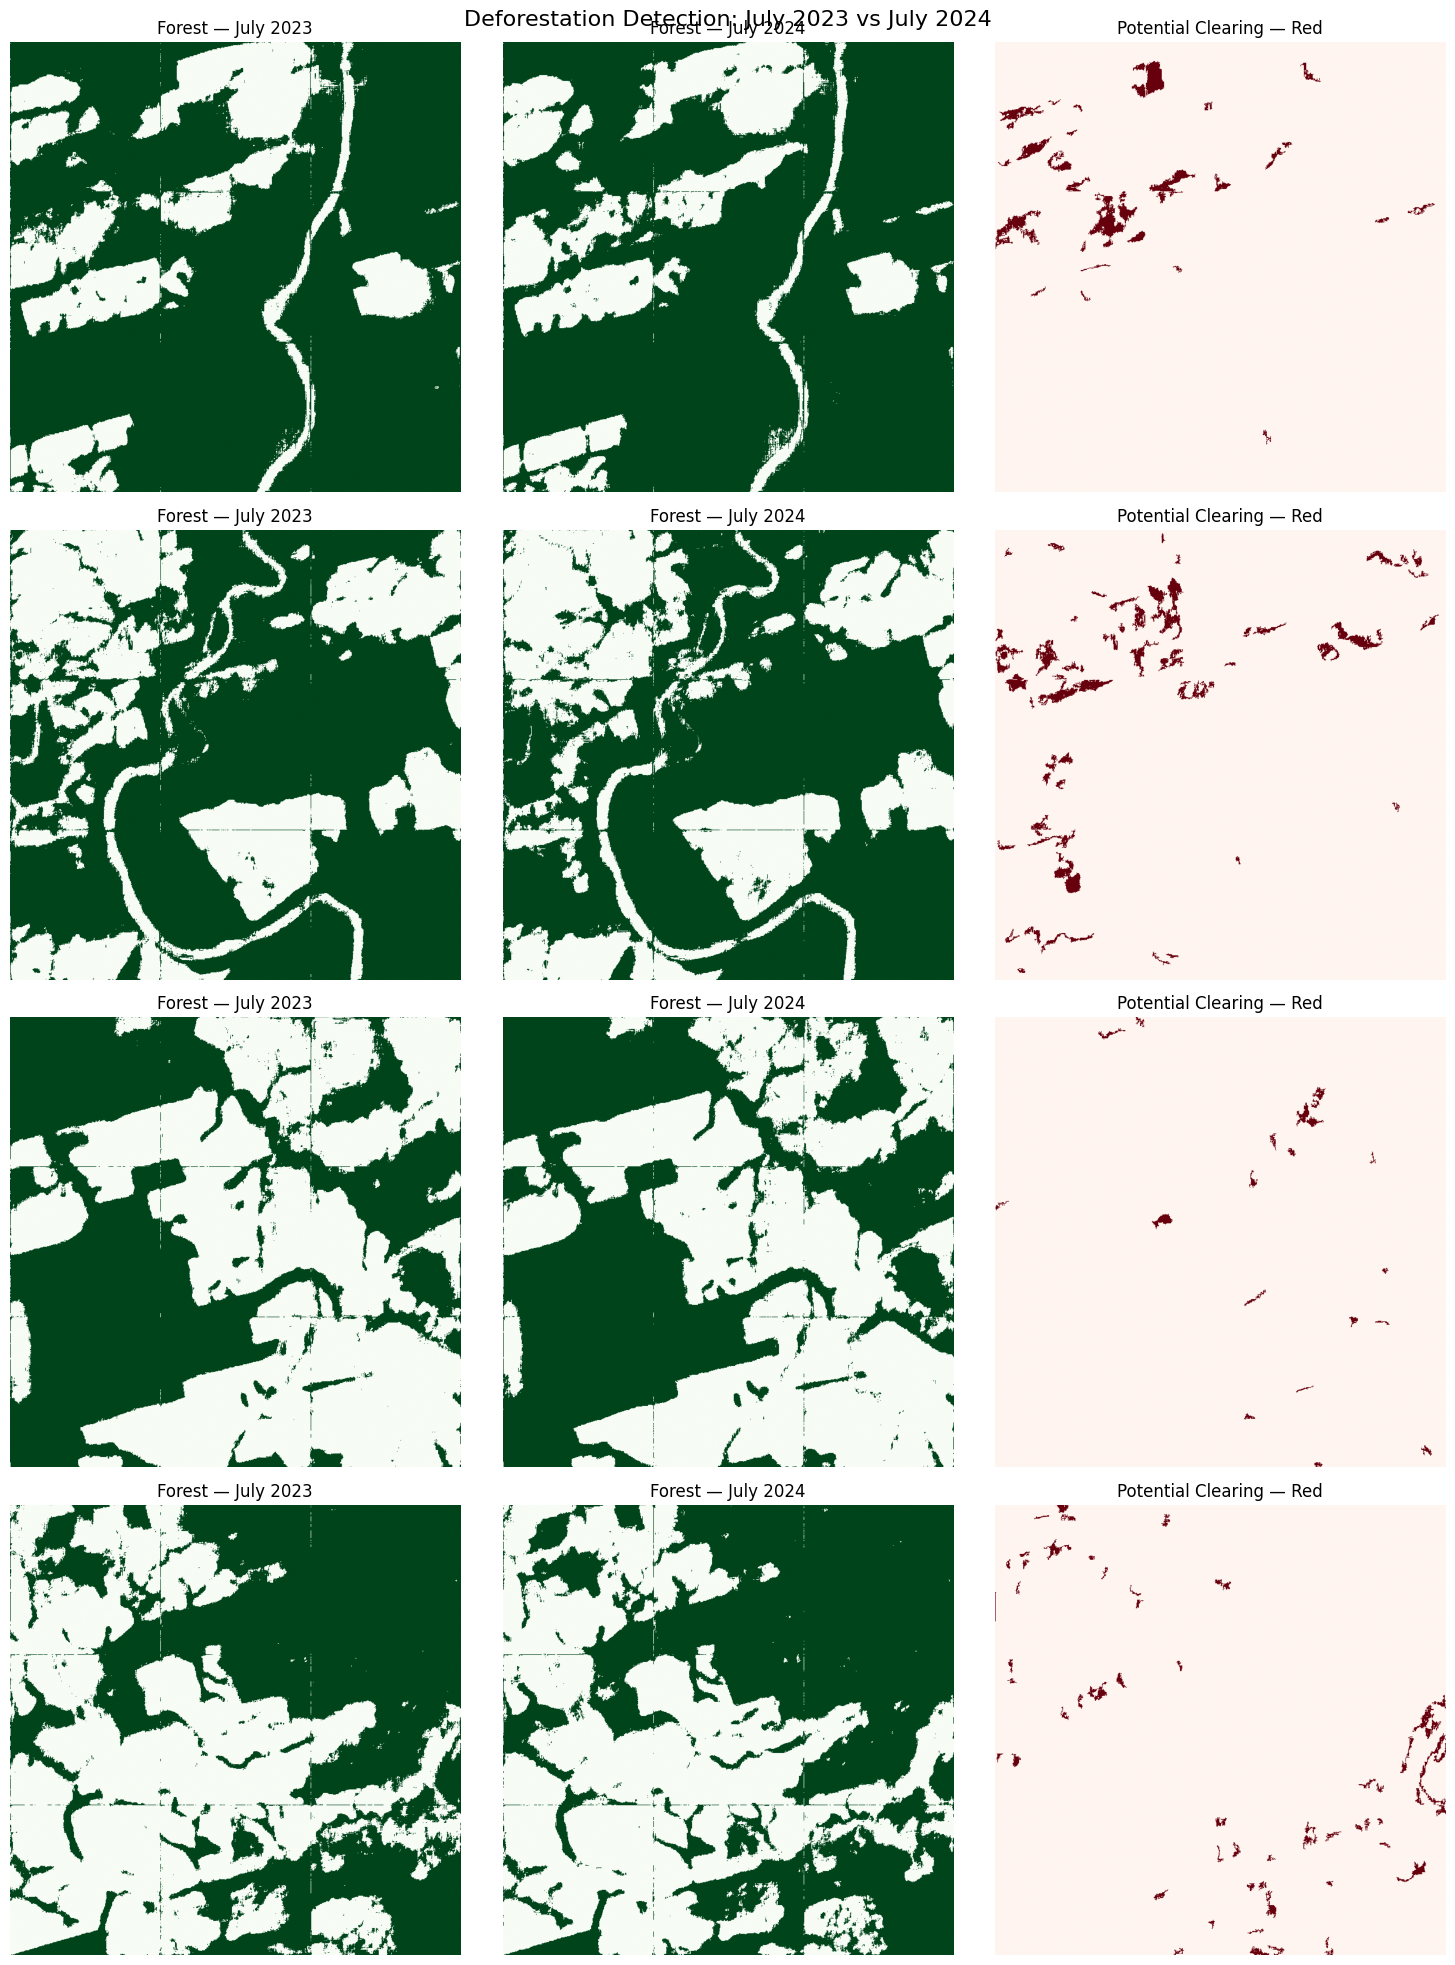

Map saved to: assets/forest_change_map.png
File exists: True


In [38]:
import os
import matplotlib.pyplot as plt
import numpy as np

os.makedirs("assets", exist_ok=True)

sections = sorted(forest_2023_maps.keys())

fig, axes = plt.subplots(
    len(sections), 3,
    figsize=(15, 5 * len(sections)),
    squeeze=False
)

for row, section in enumerate(sections):
    axes[row, 0].imshow(
        forest_2023_maps[section],
        vmin=0, vmax=1, cmap="Greens"
    )
    axes[row, 0].set_title("Forest — July 2023")

    axes[row, 1].imshow(
        forest_2024_maps[section],
        vmin=0, vmax=1, cmap="Greens"
    )
    axes[row, 1].set_title("Forest — July 2024")

    axes[row, 2].imshow(
        loss_maps[section],
        vmin=0, vmax=1, cmap="Reds"
    )
    axes[row, 2].set_title("Potential Clearing — Red")

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "Deforestation Detection: July 2023 vs July 2024",
    fontsize=16
)
plt.tight_layout()

map_path = "assets/forest_change_map.png"
plt.savefig(map_path, dpi=200, bbox_inches="tight")
plt.show()

print("Map saved to:", map_path)
print("File exists:", os.path.exists(map_path))

In [39]:
from google.colab import files
files.download("assets/forest_change_map.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
print("========== SUMMARY ==========")

print("Study area: Novo Progresso, Pará, Brazil")
print("Comparison: July 2023 vs July 2024")
print("Satellite: Sentinel-2 Level-2A")
print("Model: U-Net with ResNet-34 encoder")

print("\n--- Model evaluation ---")
print(f"U-Net IoU: {iou:.4f}")
print(f"U-Net F1-score: {f1:.4f}")
print(f"NDVI IoU: {ndvi_iou:.4f}")
print(f"NDVI F1-score: {ndvi_f1:.4f}")

print("\n--- Forest change ---")
print("Aligned tiles:", len(X_2023))
print("Potential clearing pixels:", int(clean_loss.sum()))
print(f"Estimated potential clearing: {estimated_loss_hectares:.2f} ha")

print("\n--- Validation ---")
print("All 2023 aligned images finite:", np.isfinite(X_2023).all())
print("All 2024 aligned images finite:", np.isfinite(X_2024).all())
print("Prediction shapes match:",
      pred_2023.shape == pred_2024.shape == clean_loss.shape)

print("\nSummary generated.")

========== SUMMARY ==========
Study area: Novo Progresso, Pará, Brazil
Comparison: July 2023 vs July 2024
Satellite: Sentinel-2 Level-2A
Model: U-Net with ResNet-34 encoder

--- Model evaluation ---
U-Net IoU: 0.8830
U-Net F1-score: 0.9379
NDVI IoU: 0.9048
NDVI F1-score: 0.9500

--- Forest change ---
Aligned tiles: 36
Potential clearing pixels: 39665
Estimated potential clearing: 396.65 ha

--- Validation ---
All 2023 aligned images finite: True
All 2024 aligned images finite: True
Prediction shapes match: True

Summary generated.
